# Notebook 02 — Feature Engineering

**Purpose:** Build all 18 features from the raw data.

**Prerequisite:** Notebook 01 must have run cleanly with all 6 files present.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (14, 5)

from src.data_loader import load_all_data
from src.features import build_all_features, validate_features, FEATURE_COLS

data = load_all_data()
print("\nFeature columns to be built:", len(FEATURE_COLS))
for i, col in enumerate(FEATURE_COLS, 1):
    print(f"  {i:02d}. {col}")

  Loading raw data files
  [OK] EURUSD 1H: 39,033 rows | 2020-01-01 → 2026-04-06
  [OK] EURUSD 4H: 39,033 rows | 2020-01-01 → 2026-04-06
  [OK] EURUSD Daily: 39,033 rows | 2020-01-01 → 2026-04-06
  [OK] DXY 1H: 39,033 rows | 2020-01-01 → 2026-04-06
  [OK] VIX Daily: 39,033 rows | 2020-01-01 → 2026-04-06
  [OK] US10Y Daily: 39,033 rows | 2020-01-01 → 2026-04-06
-------------------------------------------------------
  All files loaded successfully.

Feature columns to be built: 20
  01. ret_1
  02. ret_4
  03. ret_8
  04. ret_24
  05. atr_norm
  06. body_ratio
  07. range_pos_20
  08. rsi_dev_14
  09. adx_14
  10. atr_roc_8
  11. vix_regime
  12. dxy_slope
  13. us10y_direction
  14. us10y_z20
  15. rate_differential
  16. session
  17. ret_1_z24
  18. ret_4h_8
  19. rsi_dev_4h
  20. ret_1d_5


## Step 1 — Build all features

This runs all Tier A/B/D/E feature computations and shifts everything +1 bar.

In [2]:
df_features = build_all_features(
    eurusd_1h = data['eurusd_1h'],
    eurusd_4h = data['eurusd_4h'],
    eurusd_1d = data['eurusd_1d'],
    dxy_1h    = data['dxy_1h'],
    vix_1d    = data['vix_1d'],
    us10y_1d  = data['us10y_1d']
)

print(f"\nFinal DataFrame shape: {df_features.shape}")
print(f"Columns: {list(df_features.columns)}")

Building features...
  [OK] Tier A: price structure features
  [OK] Tier B: momentum features
  [OK] Rate differential (ECB minus Fed) encoded
  [OK] Tier D: regime features
  [OK] Tier E: z-scored return
  [OK] Multi-timeframe context (4H + Daily)
  [OK] All features shifted +1 bar | Final rows: 39,001

Final DataFrame shape: (39001, 26)
Columns: ['Open', 'High', 'Low', 'Close', 'Volume', 'ret_1', 'ret_4', 'ret_8', 'ret_24', 'atr_14', 'atr_norm', 'body_ratio', 'range_pos_20', 'rsi_dev_14', 'adx_14', 'atr_roc_8', 'vix_regime', 'dxy_slope', 'session', 'us10y_direction', 'us10y_z20', 'rate_differential', 'ret_1_z24', 'ret_4h_8', 'rsi_dev_4h', 'ret_1d_5']


## Step 2 — Validate features

In [3]:
validate_features(df_features)


  Feature validation report
  Shape: (39001, 26)
  Date range: 2020-01-03 → 2026-04-06

  [OK] ret_1                | null: 0.0% | mean: 0.0000 | std: 0.0010
  [OK] ret_4                | null: 0.0% | mean: 0.0000 | std: 0.0020
  [OK] ret_8                | null: 0.0% | mean: 0.0000 | std: 0.0027
  [OK] ret_24               | null: 0.0% | mean: 0.0000 | std: 0.0047
  [OK] atr_norm             | null: 0.0% | mean: 0.0013 | std: 0.0005
  [OK] body_ratio           | null: 0.0% | mean: 0.4554 | std: 0.2588
  [OK] range_pos_20         | null: 0.0% | mean: 0.4995 | std: 0.2955
  [OK] rsi_dev_14           | null: 0.0% | mean: -0.0514 | std: 12.5485
  [OK] adx_14               | null: 0.0% | mean: 26.1766 | std: 10.6008
  [OK] atr_roc_8            | null: 0.0% | mean: 0.0214 | std: 0.2210
  [OK] vix_regime           | null: 0.0% | mean: 1.1539 | std: 0.7048
  [OK] dxy_slope            | null: 0.0% | mean: 0.0365 | std: 0.9993
  [OK] us10y_direction      | null: 0.0% | mean: 0.0037 | std: 0.45

## Step 3 — Inspect sample rows

In [4]:
print("Feature columns (first 5 rows):")
df_features[FEATURE_COLS].head(10).round(5)

Feature columns (first 5 rows):


,ret_1,ret_4,ret_8,ret_24,atr_norm,body_ratio,range_pos_20,rsi_dev_14,adx_14,atr_roc_8,vix_regime,dxy_slope,us10y_direction,us10y_z20,rate_differential,session,ret_1_z24,ret_4h_8,rsi_dev_4h,ret_1d_5
Price,,,,,,,,,,,,,,,,,,,,
2020-01-03 02:00:00,-0.00009,0.00011,0.00021,-0.00444,0.00084,0.17544,0.18020,-9.80491,32.43888,-0.26402,0.0,1.0,-1.0,-4.24853,-1.75,0.0,0.09386,0.00033,-37.65920,-0.0015
2020-01-03 03:00:00,-0.00004,0.00011,0.00052,-0.00368,0.00081,0.14634,0.17030,-10.09469,31.71162,-0.26629,0.0,1.0,-1.0,-2.92404,-1.75,0.0,0.10771,-0.00055,-41.14745,-0.0015
2020-01-03 04:00:00,-0.00018,-0.00048,0.00007,-0.00277,0.00079,0.32813,0.13069,-11.29666,30.76246,-0.25331,0.0,1.0,-1.0,-2.32020,-1.75,0.0,-0.06428,-0.00055,-41.14745,0.0000
2020-01-03 05:00:00,-0.00033,-0.00064,-0.00055,-0.00340,0.00077,0.58065,0.07178,-13.48773,30.45431,-0.23483,0.0,1.0,-1.0,-1.94936,-1.75,0.0,-0.19250,-0.00055,-41.14745,0.0000
2020-01-03 06:00:00,0.00025,-0.00030,-0.00020,-0.00341,0.00075,0.50000,0.14394,-10.68778,30.22065,-0.21692,0.0,1.0,-1.0,-1.68819,-1.75,0.0,0.39882,-0.00055,-41.14745,0.0000
2020-01-03 07:00:00,-0.00143,-0.00169,-0.00159,-0.00507,0.00082,0.81959,0.02157,-19.07955,31.26466,-0.09858,0.0,1.0,0.0,0.56273,-1.75,0.0,-1.20276,-0.00299,-46.28587,0.0000
2020-01-03 08:00:00,-0.00018,-0.00169,-0.00218,-0.00544,0.00083,0.21212,0.00954,-19.94324,32.35152,-0.06818,0.0,1.0,0.0,0.56273,-1.75,0.0,0.04663,-0.00299,-46.28587,0.0000
2020-01-03 09:00:00,-0.00099,-0.00235,-0.00299,-0.00562,0.00085,0.90164,0.00159,-24.21015,34.10807,-0.02066,0.0,1.0,0.0,0.56273,-1.75,1.0,-0.73944,-0.00299,-46.28587,0.0000
2020-01-03 10:00:00,-0.00037,-0.00297,-0.00327,-0.00557,0.00087,0.32031,0.07459,-25.60051,36.22300,0.03436,0.0,1.0,0.0,0.56273,-1.75,1.0,-0.13367,-0.00299,-46.28587,0.0000


## Step 4 — Feature correlation heatmap

We want features to be as uncorrelated with each other as possible.
Any pair with correlation > 0.85 is a candidate for removal.

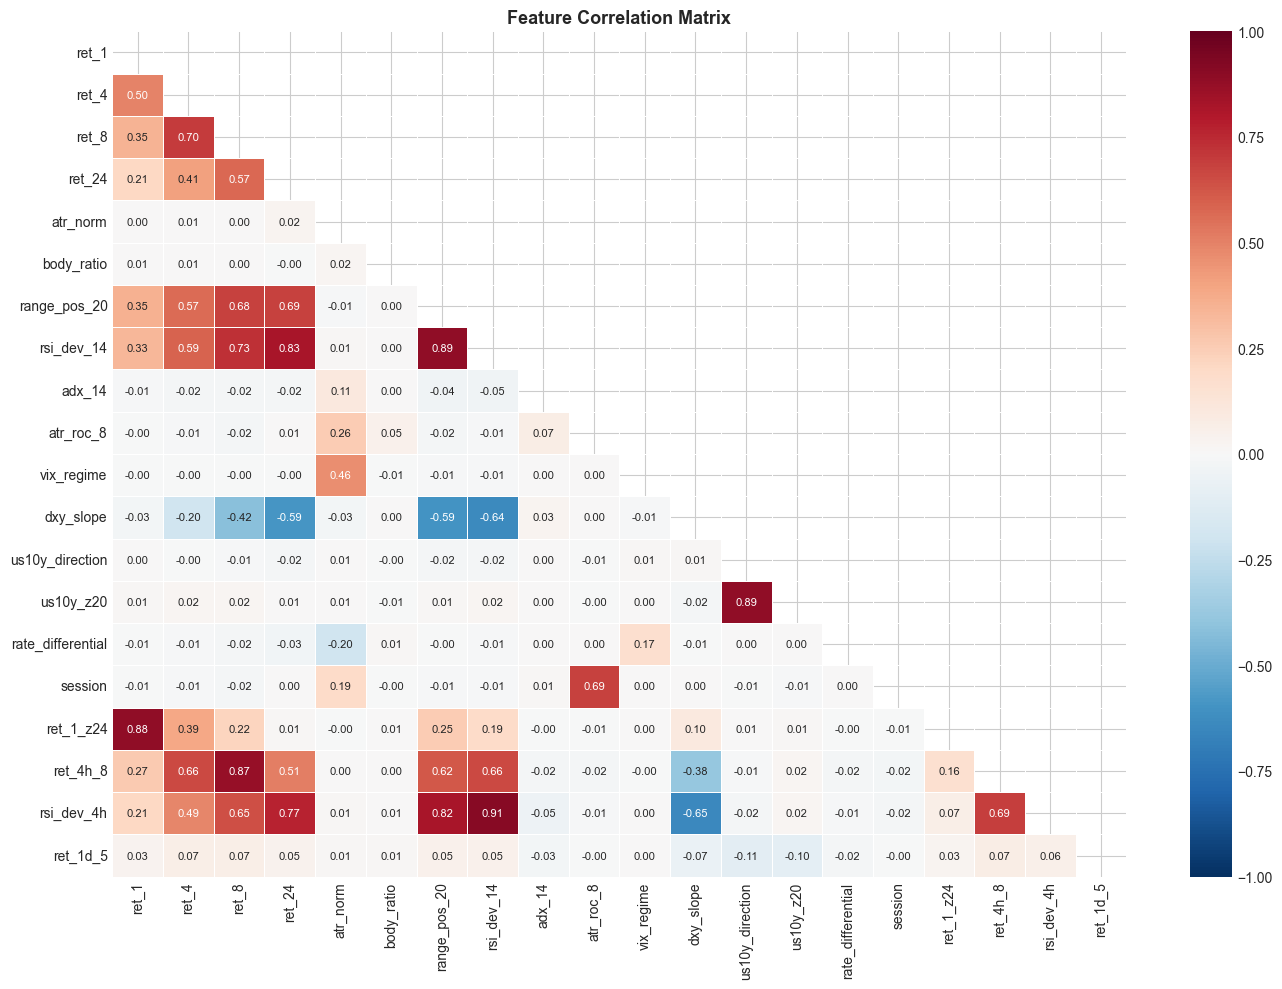

Saved to results/02_feature_correlation.png


In [5]:
fig, ax = plt.subplots(figsize=(14, 10))
corr = df_features[FEATURE_COLS].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(
    corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
    center=0, vmin=-1, vmax=1, linewidths=0.5,
    ax=ax, annot_kws={'size': 8}
)
ax.set_title('Feature Correlation Matrix', fontweight='bold', fontsize=13)
plt.tight_layout()
plt.savefig('../results/02_feature_correlation.png', dpi=120, bbox_inches='tight')
plt.show()
print("Saved to results/02_feature_correlation.png")

In [6]:
# Flag high-correlation pairs
print("Feature pairs with |correlation| > 0.70:")
print("-" * 45)
found = False
for i in range(len(FEATURE_COLS)):
    for j in range(i+1, len(FEATURE_COLS)):
        c = corr.iloc[i, j]
        if abs(c) > 0.70:
            print(f"  {FEATURE_COLS[i]:<20} vs {FEATURE_COLS[j]:<20} : {c:.3f}")
            found = True
if not found:
    print("  None found. All features have acceptable correlation.")

Feature pairs with |correlation| > 0.70:
---------------------------------------------
  ret_1                vs ret_1_z24            : 0.885
  ret_4                vs ret_8                : 0.703
  ret_8                vs rsi_dev_14           : 0.732
  ret_8                vs ret_4h_8             : 0.871
  ret_24               vs rsi_dev_14           : 0.825
  ret_24               vs rsi_dev_4h           : 0.770
  range_pos_20         vs rsi_dev_14           : 0.887
  range_pos_20         vs rsi_dev_4h           : 0.823
  rsi_dev_14           vs rsi_dev_4h           : 0.911
  us10y_direction      vs us10y_z20            : 0.885


## Step 5 — Feature distributions

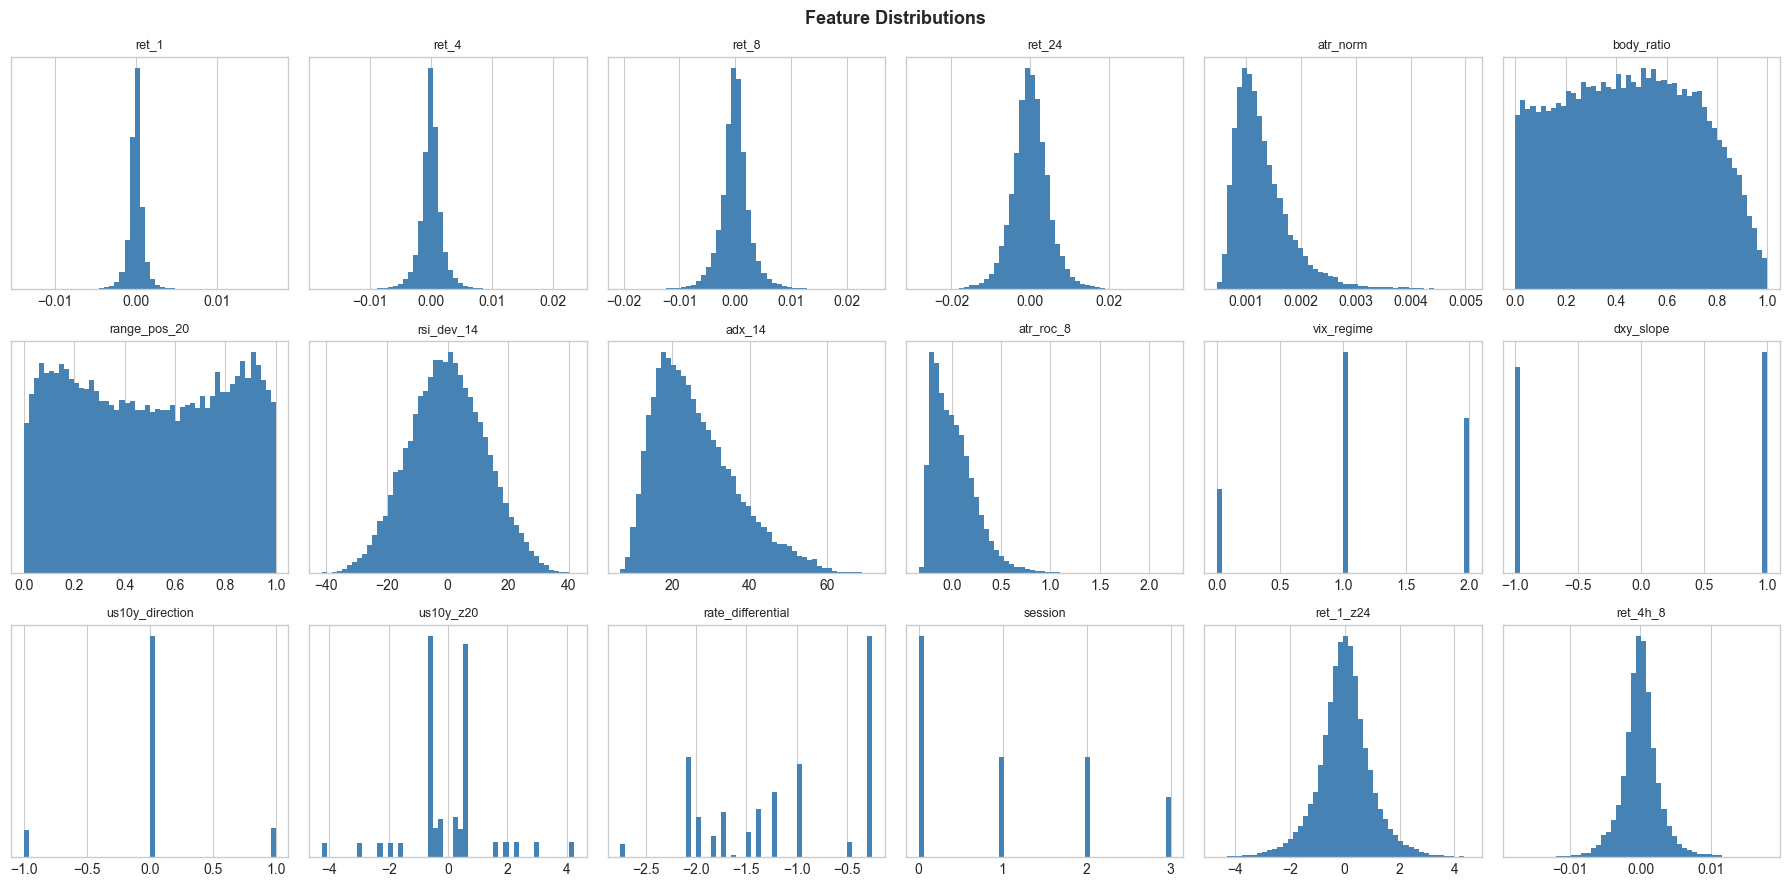

In [7]:
fig, axes = plt.subplots(3, 6, figsize=(18, 9))
axes = axes.flatten()
for i, col in enumerate(FEATURE_COLS):
    if i >= len(axes): break
    df_features[col].dropna().hist(bins=50, ax=axes[i], color='steelblue', edgecolor='none')
    axes[i].set_title(col, fontsize=9)
    axes[i].set_yticks([])
for j in range(i+1, len(axes)):
    axes[j].set_visible(False)
plt.suptitle('Feature Distributions', fontweight='bold', fontsize=13)
plt.tight_layout()
plt.savefig('../results/02_feature_distributions.png', dpi=100, bbox_inches='tight')
plt.show()

## Step 6 — Save features to disk

In [8]:
import os
os.makedirs('../features', exist_ok=True)
df_features.to_csv('../features/eurusd_features.csv')
print(f"Features saved to features/eurusd_features.csv")
print(f"Shape: {df_features.shape}")
print(f"Date range: {df_features.index[0].date()} -> {df_features.index[-1].date()}")

Features saved to features/eurusd_features.csv
Shape: (39001, 26)
Date range: 2020-01-03 -> 2026-04-06


## ✅ Checkpoint

**What to check before continuing:**

1. All 18 features show `[OK]` in the validation report (null% < 5%)
2. No feature pair has correlation > 0.85 (if so, drop one)
3. `features/eurusd_features.csv` file has been created

**What the heatmap should look like:**
- Most cells should be light/white (low correlation)
- `ret_1`, `ret_4`, `ret_8`, `ret_24` will have some correlation (that's expected — they are related)
- `vix_regime`, `session`, `day_of_week` should be nearly uncorrelated with everything else

**→ Open `03_target_construction.ipynb` next.**